# 15. EP3: aprendizaje no supervisado (fase 13; descriptivo, post hoc)

**Qué hacemos.** Agrupamos las cajas de la población principal según *cómo se ven* (distancia, azimut, puntos LiDAR, densidad y volumen) **sin mirar `sin_camara` ni nada del par 2D**, y después preguntamos si esos grupos se parecen a la tasa de cajas sin pareja y si aportan algo que la regla de puntos no tenga.

**Analogía.** Es como ordenar una caja de fotos por parecido (cercanas y nítidas, lejanas y borrosas) antes de saber cuáles fueron archivadas: después vemos si las borrosas se archivan menos.

**Rótulo:** no está en el plan v3, así que todo lo de este notebook es **post hoc, no pre-declarado**. EP2 usó además variables de oclusión que no están en `dev_41`, por lo que la comparación con EP2 no es idéntica.

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists()), Path("C:/Users/maico/waymo-evaluacion"))
sys.path.insert(0, str(RAIZ / "src"))
REP, IMG, APP = RAIZ / "data/08_reporting_ep3", RAIZ / "images/ep3", RAIZ / "data/09_app_ep3"
IMG.mkdir(parents=True, exist_ok=True)
RECALCULAR = False          # True: vuelve a correr los scripts de esta fase (puede tardar mucho; escribe solo en *_ep3)
SEMILLA = 42
EN_MUESTRA = "en muestra: 41 segmentos, parámetros del detector ajustados con los mismos datos; post hoc, no pre-declarado; sin validación con datos nuevos"
GANANCIA_C = "La ganancia del brazo C sale de 2 celdas cámara x segmento, una de ellas en el segmento donde se descubrió el hueco."
AZUL, NARANJA, GRIS, VERDE, ROJO = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e", "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

from waymo_evaluacion.ep3.plan import verificar_plan_v3
print("Plan v3 verificado (sha256):", ", ".join(verificar_plan_v3(RAIZ)))


def coma(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


def miles(x):
    return f"{int(round(x)):,}".replace(",", ".")


def guardar_fig(fig, nombre):
    fig.savefig(IMG / f"{nombre}.png", dpi=130, bbox_inches="tight")


def correr(script, *args):
    r = subprocess.run([sys.executable, "-X", "utf8", str(RAIZ / "scripts/ep3" / script), *args], capture_output=True, text=True, cwd=RAIZ)
    print(r.stdout[-1500:], r.stderr[-800:])
    assert r.returncode == 0, f"{script} fallo"

Plan v3 verificado (sha256): plan_v3.md, plan_v3.json


Cajas: 80.571 | variables: distancia_m, azimut_abs_deg, log_puntos, log_densidad, log_volumen | muestras: silhouette 20.000, GMM y Ward 15.000


,k,silhouette_muestra_20000,davies_bouldin,calinski_harabasz,tamano_cluster_mas_chico,BIC_GMM_muestra_15000
0,2,0.317,1.200,47413.992,0.460,86283.005
1,3,0.248,1.369,37420.444,0.272,66153.390
2,4,0.243,1.222,33140.722,0.198,56734.221
3,5,0.240,1.244,31196.261,0.110,48493.657
4,6,0.247,1.186,29711.882,0.091,26202.999
5,7,0.232,1.172,28324.866,0.083,22449.363
6,8,0.232,1.168,27080.174,0.079,14497.301


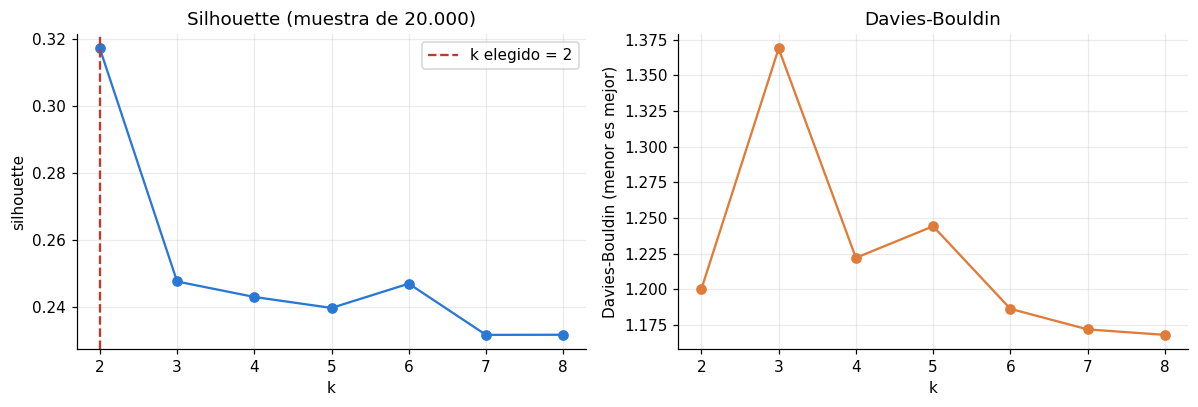

**Lectura (generada).** Entre k = 2 y 6 el máximo silhouette es k = 2 (0,317); se explora también k = 4 como en EP2 (0,243).

In [2]:
if RECALCULAR:
    correr("f13_no_supervisado.py")
r13 = json.loads((REP / "f13_resumen.json").read_text(encoding="utf-8"))
k_el = r13["k_elegido"]
selk = pd.read_csv(REP / "f13_seleccion_k.csv")
print(f"Cajas: {miles(r13['filas'])} | variables: {', '.join(r13['variables'])} | muestras: silhouette {miles(r13['muestras']['silhouette'])}, GMM y Ward {miles(r13['muestras']['gmm_y_ward'])}")
display(selk.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(selk["k"], selk["silhouette_muestra_20000"], "o-", color=AZUL); axes[0].axvline(k_el, color=ROJO, ls="--", label=f"k elegido = {k_el}"); axes[0].set_xlabel("k"); axes[0].set_ylabel("silhouette"); axes[0].legend(); axes[0].set_title("Silhouette (muestra de 20.000)")
axes[1].plot(selk["k"], selk["davies_bouldin"], "o-", color=NARANJA); axes[1].set_xlabel("k"); axes[1].set_ylabel("Davies-Bouldin (menor es mejor)"); axes[1].set_title("Davies-Bouldin")
fig.tight_layout(); guardar_fig(fig, "15_seleccion_k"); plt.show()
display(Markdown(f"**Lectura (generada).** Entre k = 2 y 6 el máximo silhouette es k = {k_el} ({coma(selk.set_index('k').loc[k_el, 'silhouette_muestra_20000'])}); se explora también k = 4 como en EP2 ({coma(selk.set_index('k').loc[4, 'silhouette_muestra_20000'])})."))

## Estructura: ¿los grupos son firmes?
Acuerdo entre técnicas (ARI de KMeans, GMM y Ward en una muestra de 15.000) y estabilidad al remuestrear segmentos (30 réplicas).

In [3]:
display(pd.DataFrame(r13["ari_entre_tecnicas"]).T.round(3))
display(pd.read_csv(REP / "f13_estabilidad.csv").round(3))
a2 = r13["ari_entre_tecnicas"]["k=2"]
display(Markdown(f"**Lectura (generada).** El acuerdo entre técnicas es bajo (KMeans contra GMM {coma(a2['KMeans vs GMM'])}, contra Ward {coma(a2['KMeans vs Ward'])} con k = 2): los grupos son una partición cómoda de un continuo, no grupos naturales firmes. La estabilidad al remuestrear segmentos es alta con k = 2 y baja con k = 4."))

,KMeans vs GMM,KMeans vs Ward,GMM vs Ward
k=2,0.008,0.426,0.082
k=4,0.265,0.354,0.079


,k,remuestreos,ari_medio,ari_minimo,ari_p5,nota
0,2,30,0.93,0.815,0.853,KMeans n_init=3 en cada remuestreo (el modelo ...
1,4,30,0.66,0.401,0.423,KMeans n_init=3 en cada remuestreo (el modelo ...


**Lectura (generada).** El acuerdo entre técnicas es bajo (KMeans contra GMM 0,008, contra Ward 0,426 con k = 2): los grupos son una partición cómoda de un continuo, no grupos naturales firmes. La estabilidad al remuestrear segmentos es alta con k = 2 y baja con k = 4.

## Cruce con `sin_camara`, perfil y comparación con la regla
Tasa de `sin_camara` por cluster con IC 95 % por segmentos; probabilidad media que predice la regla (Platt) contra la tasa observada.

### k = 2

,cluster,tipo_de_caso,cajas,pct_cajas,tasa_sin_camara,ic_lo,ic_hi,segmentos,mediana_distancia_m,mediana_num_lidar_points,mediana_densidad_puntos,prob_media_regla_platt,diferencia_tasa_menos_prob_regla,AUC_regla_dentro_del_cluster
0,0,cercanos y densos,37094,0.46,0.089,0.044,0.147,40,21.116,108.5,95.395,0.067,0.022,0.531
1,1,lejanos y poco densos,43477,0.54,0.318,0.254,0.384,41,49.507,16.0,13.467,0.337,-0.019,0.837


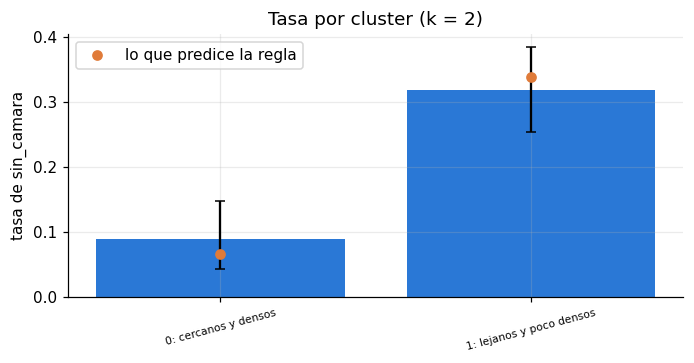

### k = 4

,cluster,tipo_de_caso,cajas,pct_cajas,tasa_sin_camara,ic_lo,ic_hi,segmentos,mediana_distancia_m,mediana_num_lidar_points,mediana_densidad_puntos,prob_media_regla_platt,diferencia_tasa_menos_prob_regla,AUC_regla_dentro_del_cluster
0,0,cercanos y densos,20156,0.250,0.081,0.023,0.167,40,14.761,188.0,175.657,0.045,0.036,0.416
1,1,a distancia media y de densidad media,15948,0.198,0.148,0.107,0.186,37,36.266,30.0,39.729,0.187,-0.040,0.687
2,2,lejanos y poco densos,19007,0.236,0.546,0.451,0.627,40,58.882,5.0,4.349,0.529,0.017,0.819
3,3,a distancia media y de densidad media,25460,0.316,0.107,0.072,0.149,40,38.764,44.0,28.105,0.125,-0.018,0.622


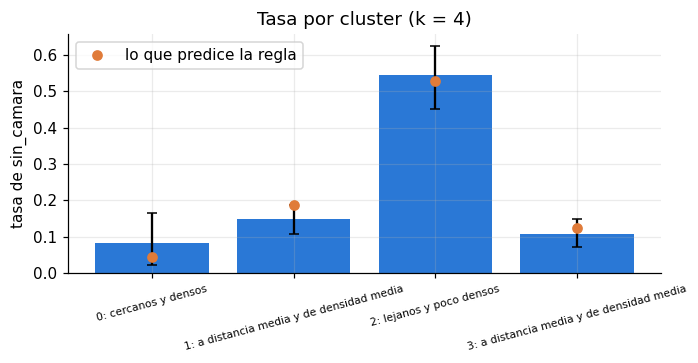

In [4]:
for k in sorted({k_el, 4}):
    cl = pd.read_csv(REP / f"f13_clusters_k{k}.csv")
    display(Markdown(f"### k = {k}"))
    display(cl[["cluster", "tipo_de_caso", "cajas", "pct_cajas", "tasa_sin_camara", "ic_lo", "ic_hi", "segmentos", "mediana_distancia_m", "mediana_num_lidar_points", "mediana_densidad_puntos", "prob_media_regla_platt", "diferencia_tasa_menos_prob_regla", "AUC_regla_dentro_del_cluster"]].round(3))
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.bar([f"{r.cluster}: {r.tipo_de_caso}" for r in cl.itertuples()], cl["tasa_sin_camara"], yerr=[cl["tasa_sin_camara"] - cl["ic_lo"], cl["ic_hi"] - cl["tasa_sin_camara"]], color=AZUL, capsize=3)
    ax.plot(range(len(cl)), cl["prob_media_regla_platt"], "o", color=NARANJA, label="lo que predice la regla"); ax.set_ylabel("tasa de sin_camara"); ax.tick_params(axis="x", labelsize=7, rotation=15); ax.legend(); ax.set_title(f"Tasa por cluster (k = {k})")
    fig.tight_layout(); guardar_fig(fig, f"15_clusters_k{k}"); plt.show()

## ¿Aportan algo que la regla no tenga?
Regresión logística sobre el logit de la probabilidad de la regla, con y sin indicadoras de cluster; GroupKFold(5) por segmento e IC por segmentos.

In [5]:
ap = pd.read_csv(REP / "f13_aporte_cluster.csv")
display(ap.drop(columns=["metodo"]).round(4))
a = ap.set_index("k")
display(Markdown(f"**Lectura (generada).** Con k = 2 el cambio de AUC es {coma(a.loc[2, 'dif_AUC'], 4)} (IC {coma(a.loc[2, 'ic_lo'], 4)} a {coma(a.loc[2, 'ic_hi'], 4)}); con k = 4, {coma(a.loc[4, 'dif_AUC'], 4)} (IC {coma(a.loc[4, 'ic_lo'], 4)} a {coma(a.loc[4, 'ic_hi'], 4)}). **Los clusters no mejoran la predicción de la regla**; con k = 4 incluso la empeoran de forma distinguible."))

,k,AUC_regla,AUC_regla_mas_cluster,dif_AUC,ic_lo,ic_hi,Brier_regla,Brier_regla_mas_cluster,excluye_0
0,2,0.7982,0.7967,-0.0015,-0.0055,0.0023,0.1173,0.1170,False
1,4,0.7982,0.7885,-0.0097,-0.0150,-0.0044,0.1173,0.1171,True


**Lectura (generada).** Con k = 2 el cambio de AUC es -0,0015 (IC -0,0055 a 0,0023); con k = 4, -0,0097 (IC -0,0150 a -0,0044). **Los clusters no mejoran la predicción de la regla**; con k = 4 incluso la empeoran de forma distinguible.

## IsolationForest (contaminación 1 %) y comparación con EP2

In [6]:
iso = r13["isolation_forest"]
print(f"Atípicas: {miles(iso['cajas_atipicas'])} ({pct(iso['porcentaje'])}) en {iso['segmentos_con_atipicos']} de {iso['segmentos_total']} segmentos | tasa de sin_camara: atípicas {pct(iso['tasa_sin_camara_atipicas'])} (IC {pct(iso['ic_atipicas'][0])} a {pct(iso['ic_atipicas'][1])}) contra resto {pct(iso['tasa_sin_camara_resto'])}")
display(pd.DataFrame(iso["top3_segmentos_aportan"]))
cn = pd.read_csv(REP / "f13_comparacion_ep2_ep3.csv")
display(cn.round(3))
display(Markdown("**Lectura (generada).** Los resultados **cambian** respecto de EP2 (silhouette, tasa del cluster de mayor tasa y tasa de los atípicos bajan). Una causa probable es que aquí no hay variables de oclusión y que se usan 41 segmentos en vez de 33; es una hipótesis, no verificada. Los atípicos siguen teniendo mucha más tasa de cajas sin pareja que el resto."))

Atípicas: 806 (1,0 %) en 36 de 41 segmentos | tasa de sin_camara: atípicas 68,1 % (IC 49,2 % a 84,5 %) contra resto 20,8 %


,seg,atipicos,pct_de_los_atipicos
0,182443342825,102,0.126551
1,198898761683,93,0.115385
2,161536078775,85,0.105459


,medida,EP2,EP3,fuente_EP2,fuente_EP3
0,k elegido (maximo silhouette),2.000,2.000,08_no_supervisado_resumen.json,f13_seleccion_k.csv
1,silhouette con k=2,0.387,0.317,08_clusters_seleccion_k.csv,f13_seleccion_k.csv
2,silhouette con k=4,0.251,0.243,08_clusters_seleccion_k.csv,f13_seleccion_k.csv
3,tasa sin_camara del cluster de mayor tasa con ...,62.706,54.575,"08_clusters_vs_franja.csv (cluster 'lejanos, p...",f13_clusters_k4.csv (cluster 2: lejanos y poco...
4,IsolationForest: tasa sin_camara de atipicas (%),80.300,68.114,08_no_supervisado_resumen.json,f13_isolation_forest.csv
5,IsolationForest: tasa de las no atipicas (%),22.600,20.752,08_no_supervisado_resumen.json,f13_isolation_forest.csv
6,IsolationForest: segmentos que aportan atipicos,28.000,36.000,08_no_supervisado_resumen.json,f13_isolation_forest.csv
7,estabilidad: ARI medio al remuestrear segmento...,0.953,0.930,08_no_supervisado_resumen.json,f13_estabilidad.csv
8,estabilidad: ARI minimo (k elegido),0.301,0.815,08_no_supervisado_resumen.json,f13_estabilidad.csv
9,ARI KMeans vs GMM (k elegido),0.997,0.008,08_no_supervisado_resumen.json,f13_resumen.json


**Lectura (generada).** Los resultados **cambian** respecto de EP2 (silhouette, tasa del cluster de mayor tasa y tasa de los atípicos bajan). Una causa probable es que aquí no hay variables de oclusión y que se usan 41 segmentos en vez de 33; es una hipótesis, no verificada. Los atípicos siguen teniendo mucha más tasa de cajas sin pareja que el resto.

## Artefacto y uso en la página

In [7]:
r = subprocess.run([sys.executable, "-X", "utf8", str(RAIZ / "scripts/ep3/verificar_no_supervisado.py")], capture_output=True, text=True, cwd=RAIZ)
print(r.stdout.strip())
display(Markdown("El scaler y el KMeans se guardan en `data/06_models_ep3/no_supervisado_v3.joblib` con su sha256 en `manifest_no_supervisado.json` (independiente de `manifest_v3.json`). **No se usan para puntuar**: la página solo muestra el «tipo de caso» de cada caja con su tasa histórica, y avisa que es una descripción y no mejora la predicción."))

IGUAL    no_supervisado_v3.joblib
no supervisado (k = 2, creado 2026-11-14T13:03:31): coinciden 1 de 1 archivos


El scaler y el KMeans se guardan en `data/06_models_ep3/no_supervisado_v3.joblib` con su sha256 en `manifest_no_supervisado.json` (independiente de `manifest_v3.json`). **No se usan para puntuar**: la página solo muestra el «tipo de caso» de cada caja con su tasa histórica, y avisa que es una descripción y no mejora la predicción.

## Diagnóstico del ARI y AUC por cluster sin celdas con hueco (post hoc, no pre-declarado; F18-A3 y A5)
`f13_ari_diagnostico.csv`: el ARI de 0,008 es del GMM de covarianza `full`; con GMM esférico y diagonal KMeans coincide (0,884 y 0,729). `f13_auc_cluster_sin_huecos.csv`: el AUC de la regla en los clusters cercanos sube al sacar las celdas con hueco.

In [8]:
diag = pd.read_csv(REP / "f13_ari_diagnostico.csv")
display(diag[diag["covarianza"].notna()][["k", "covarianza", "n_init", "converged", "n_iter", "tamanos", "ARI_vs_KMeans", "ARI_vs_Ward"]].round(3))
auc = pd.read_csv(REP / "f13_auc_cluster_sin_huecos.csv")
display(auc[["k", "cluster", "tipo_de_caso", "cajas", "cajas_en_celdas_con_hueco", "AUC_todas", "AUC_sin_celdas_con_hueco", "dif_AUC"]].round(3))

,k,covarianza,n_init,converged,n_iter,tamanos,ARI_vs_KMeans,ARI_vs_Ward
2,2,full,2.0,True,18.0,"[10471, 4529]",0.008,0.082
3,2,full,10.0,True,18.0,"[4532, 10468]",0.008,0.081
4,2,diag,2.0,True,8.0,"[5884, 9116]",0.729,0.271
5,2,diag,10.0,True,8.0,"[5883, 9117]",0.729,0.271
6,2,spherical,2.0,True,3.0,"[6533, 8467]",0.884,0.362
7,2,spherical,10.0,True,3.0,"[8536, 6464]",0.867,0.353
10,4,full,2.0,True,31.0,"[6730, 2382, 4469, 1419]",0.265,0.079
11,4,full,10.0,True,55.0,"[2335, 4251, 2560, 5854]",0.246,0.077
12,4,diag,2.0,True,36.0,"[4839, 1808, 3179, 5174]",0.309,0.443
13,4,diag,10.0,True,24.0,"[3748, 3230, 2795, 5227]",0.345,0.452


,k,cluster,tipo_de_caso,cajas,cajas_en_celdas_con_hueco,AUC_todas,AUC_sin_celdas_con_hueco,dif_AUC
0,2,0,cercanos y densos,37094,1772,0.531,0.748,0.217
1,2,1,lejanos y poco densos,43477,173,0.837,0.842,0.005
2,4,0,cercanos y densos,20156,1230,0.416,0.750,0.334
3,4,1,a distancia media y de densidad media,15948,348,0.687,0.742,0.055
4,4,2,lejanos y poco densos,19007,17,0.819,0.819,-0.000
5,4,3,a distancia media y de densidad media,25460,350,0.622,0.652,0.030
